# 7. Cosmological constraints from distance measurements

This notebook follows Sec. 4.1 of Paper I.
We forecast what BAO distance ratios at the seven redshifts of DESI DR2 constrain, with the BBN prior on $\omega_{\rm b}$, at four fractional precisions.
It builds the mock measurement, the Jacobian, the Fisher matrix and its validity test, and ends on the forecast figure, with DESI DR2's own posteriors drawn over it.
The DESI posteriors come from the tutorial data bundle (notebook 00).

In [1]:
import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

from importlib.metadata import version

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import _helpers as T
T.paper_style()
FAST = T.fast_mode()
for name in ("ggah_mod", "emu_pk", "jax", "numpy"):
    print(f"{name:9s} {version(name)}")
print("FAST =", FAST)

import matplotlib
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from ggah_mod.cosmology import PLANCK18, comoving_distance, hubble_e, r_drag
from ggah_mod.cosmology.background import transverse_distance
from ggah_mod.cosmology.drag import drag_domain_violations

c = PLANCK18

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


ggah_mod  1.7.0
emu_pk    2.1.1
jax       0.10.2
numpy     2.4.6
FAST = False


## The mock measurement

A BAO measurement returns three distances as ratios to the sound horizon $r_{\rm d}$: the transverse $f_K(\chi)$, the radial $D_H/E(z) = c/H(z)$, and, where the two cannot be separated, the isotropic $D_V = (z f_K^2 D_H/E)^{1/3}$.
DESI DR2 measures them in seven bins (Abdul Karim et al. 2025, Table 4): $D_V/r_{\rm d}$ alone at $z_{\rm eff} = 0.295$ (BGS), and $f_K/r_{\rm d}$ and $D_H/E\,r_{\rm d}$ at the six others.
We place our measurements at these seven redshifts, thirteen ratios in all, each with the same fractional error $\sigma$ and uncorrelated.

In [2]:
Z = np.array([0.295, 0.510, 0.706, 0.934, 1.321, 1.484, 2.330])
TRACER = ("BGS", "LRG1", "LRG2", "LRG3+ELG1", "ELG2", "QSO", "Lya")
ISO = np.array([True, False, False, False, False, False, False])     # D_V only
SIGMAS = (0.0003, 0.001, 0.003, 0.01)                                 # fractional error per ratio
COLOURS = ("#0b2545", "#1f6fb2", "#2ca58d", "#d1495b")
P = ("Omega_m", "Omega_b", "h", "w0", "wa", "Omega_k")                # the free parameters
n, npar = len(Z), len(P)


def ln_bao(t, z, params=P, cosmo=c):
    """[ln f_K/r_d, ln D_H/(E r_d)] at the values t of params."""
    cc = cosmo.replace(**dict(zip(params, t)))
    zj = jnp.asarray(z)
    rd = r_drag(cc)
    fk = transverse_distance(comoving_distance(zj, cc), cc)
    return jnp.concatenate([jnp.log(fk / rd), jnp.log(cc.hubble_distance / hubble_e(zj, cc) / rd)])


def observed():
    """(Mo, b): the measured log-ratios are Mo @ ln_bao + b; ln D_V = (2 ln f_K + ln D_H/E + ln z)/3."""
    rows, b = [], []
    for block in (0, 1):
        for i in np.flatnonzero(~ISO):
            r = np.zeros(2 * n)
            r[block * n + i] = 1.0
            rows.append(r)
            b.append(0.0)
    for i in np.flatnonzero(ISO):
        r = np.zeros(2 * n)
        r[i], r[n + i] = 2 / 3, 1 / 3
        rows.append(r)
        b.append(np.log(Z[i]) / 3)
    return np.array(rows), np.array(b)


Mo, bo = observed()
t0 = np.array([float(getattr(c, p)) for p in P])
d0 = np.asarray(ln_bao(jnp.asarray(t0), Z))
print(f"{len(Mo)} ratios; r_d = {float(r_drag(c)):.3f} Mpc/h")

13 ratios; r_d = 99.086 Mpc/h


## The prior, the model and the Jacobian

The ratios carry no unit, and $h$ enters them only through $r_{\rm d}$, which depends on $\omega_{\rm b}$ and $\omega_{\rm cb}$.
Alone, they constrain neither $h$ nor $\Omega_{\rm b}$.
We add the BBN prior DESI DR2 uses, $\omega_{\rm b} = 0.02218\pm0.00055$ (Schöneberg 2024, Eq. 5.1), centred on our fiducial since a Fisher matrix needs only its width.
The Fisher matrix is (Eq. 45)

$$F_{ij} = \frac{1}{\sigma^2}\sum_D \frac{\partial\ln(D/r_{\rm d})}{\partial\theta_i}\frac{\partial\ln(D/r_{\rm d})}{\partial\theta_j} + \frac{g_i g_j}{\sigma_{\omega_{\rm b}}^2},\qquad g_i = \frac{\partial\omega_{\rm b}}{\partial\theta_i}.$$

The Jacobian is one `jax.jacfwd` of the model, $r_{\rm d}$ included.
We check one column of it against central differences.

In [3]:
SIG_WB = 0.00055


def bbn_prior(t, params=P):
    t = dict(zip(params, t))
    g = np.zeros(len(params))
    g[params.index("Omega_b")] = t["h"] ** 2
    g[params.index("h")] = 2 * t["Omega_b"] * t["h"]
    return np.outer(g, g) / SIG_WB**2


J = np.asarray(jax.jacfwd(lambda t: ln_bao(t, Z))(jnp.asarray(t0)))
Jo = Mo @ J
Fp = bbn_prior(t0)

i = P.index("w0")
e = np.zeros(npar)
e[i] = 1e-5
fd = (np.asarray(ln_bao(jnp.asarray(t0 + e), Z)) - np.asarray(ln_bao(jnp.asarray(t0 - e), Z))) / 2e-5
print(f"w0 column: max |autodiff - finite difference| = {np.max(np.abs(J[:, i] - fd)):.1e}")


def fisher(sig, cols=range(npar), rows=slice(None), prior=True):
    cols = list(cols)
    Jr = Jo[rows][:, cols]
    F = Jr.T @ Jr / sig**2
    return F + Fp[np.ix_(cols, cols)] if prior else F


cov = {s: np.linalg.inv(fisher(s)) for s in SIGMAS}
print(f"condition number at 1%: {np.linalg.cond(fisher(0.01, prior=False)):.0e} without the prior, "
      f"{np.linalg.cond(fisher(0.01)):.0e} with it   (paper: 2e11, 2e6)")

w0 column: max |autodiff - finite difference| = 4.5e-11
condition number at 1%: 2e+11 without the prior, 2e+06 with it   (paper: 2e11, 2e6)


## Marginal errors

$F^{-1}$ is the covariance of $\theta$; the marginal error on each parameter is the square root of its diagonal.
Without the prior $F\propto\sigma^{-2}$ and every error would scale as $\sigma$; with it the shapes differ, because the prior sets $h$ at low precision and the ratios at high.

In [4]:
for s in SIGMAS:
    sd = np.sqrt(np.diag(cov[s]))
    print(f"{100 * s:5g}%  " + "  ".join(f"{p}={x:.3g}" for p, x in zip(P, sd)))
sd1 = np.sqrt(np.diag(cov[0.01]))
ratio_h = np.sqrt(cov[0.01][2, 2] / cov[0.001][2, 2])
print(f"sigma(h) at 1% / sigma(h) at 0.1% = {ratio_h:.2f}   (paper: 4.2; 10 without the prior)")

 0.03%  Omega_m=0.00132  Omega_b=0.000579  h=0.00441  w0=0.00781  wa=0.0346  Omega_k=0.00101
  0.1%  Omega_m=0.00439  Omega_b=0.00064  h=0.00478  w0=0.026  wa=0.115  Omega_k=0.00338
  0.3%  Omega_m=0.0132  Omega_b=0.00103  h=0.00729  w0=0.0781  wa=0.346  Omega_k=0.0101
    1%  Omega_m=0.0439  Omega_b=0.00291  h=0.02  w0=0.26  wa=1.15  Omega_k=0.0338
sigma(h) at 1% / sigma(h) at 0.1% = 4.17   (paper: 4.2; 10 without the prior)


Nested models show where the information goes: in flat $\Lambda$CDM the ratios and the prior constrain $h$ to below one per cent, and each dark-energy parameter freed costs a large factor.

In [5]:
for k in range(3, npar + 1):
    sd = np.sqrt(np.diag(np.linalg.inv(fisher(0.01, cols=range(k)))))
    print(f"{'+'.join(P[:k]):34s} " + "  ".join(f"{p}={x:.3g}" for p, x in zip(P[:k], sd)))

c2 = cov[0.01][np.ix_([3, 4], [3, 4])]
one_m_a = -c2[0, 1] / c2[1, 1]
z_p = 1 / (1 - one_m_a) - 1
sig_wp = np.sqrt(c2[0, 0] - c2[0, 1] ** 2 / c2[1, 1])
corr = cov[0.01] / np.outer(sd1, sd1)
print(f"pivot at 1%: z_p = {z_p:.2f}, sigma(w_p) = {sig_wp:.3f}   (paper: 0.27, 0.082)")
print(f"corr(h, Omega_b) = {corr[1, 2]:+.2f} at 1%   (paper: -0.91)")

Omega_m+Omega_b+h                  Omega_m=0.00782  Omega_b=0.000803  h=0.00582
Omega_m+Omega_b+h+w0               Omega_m=0.00784  Omega_b=0.00282  h=0.0193  w0=0.0727
Omega_m+Omega_b+h+w0+wa            Omega_m=0.0423  Omega_b=0.00285  h=0.0196  w0=0.256  wa=1.15
Omega_m+Omega_b+h+w0+wa+Omega_k    Omega_m=0.0439  Omega_b=0.00291  h=0.02  w0=0.26  wa=1.15  Omega_k=0.0338
pivot at 1%: z_p = 0.27, sigma(w_p) = 0.082   (paper: 0.27, 0.082)
corr(h, Omega_b) = -0.91 at 1%   (paper: -0.91)


## Is the Fisher matrix the likelihood?

We step $\pm1\sigma$ along each principal direction of $F^{-1}$, where a Gaussian likelihood has $\Delta\chi^2 = 1$ exactly, and evaluate the exact $\chi^2$ of the full model, prior included.
A point outside the range $r_{\rm d}$ is calibrated on is refused rather than extrapolated, and a precision with such a point is drawn dashed.

In [6]:
wb0 = t0[1] * t0[2] ** 2
chi2max, refused_at = {}, {}
for s in SIGMAS:
    w, v = np.linalg.eigh(cov[s])
    vals, refused = [], 0
    for kk in range(npar):
        for sgn in (1.0, -1.0):
            t = t0 + sgn * np.sqrt(w[kk]) * v[:, kk]
            try:
                r = Mo @ (np.asarray(ln_bao(jnp.asarray(t), Z)) - d0)
            except ValueError:
                refused += 1
                print(f"  {100 * s:g}%: refused, w_a = {t[4]:+.2f}, violates "
                      + ", ".join(sorted(drag_domain_violations(c.replace(**dict(zip(P, t)))))))
                continue
            vals.append(float(r @ r) / s**2 + ((t[1] * t[2] ** 2 - wb0) / SIG_WB) ** 2)
    chi2max[s], refused_at[s] = max(vals), refused
    print(f"{100 * s:5g}%  max chi^2 at 1 sigma = {max(vals):.3f}, {refused} points refused")
INVALID = {s for s in SIGMAS if chi2max[s] > 2.0 or refused_at[s] > 0}

 0.03%  max chi^2 at 1 sigma = 1.067, 0 points refused
  0.1%  max chi^2 at 1 sigma = 1.027, 0 points refused
  0.3%  max chi^2 at 1 sigma = 1.191, 0 points refused
  1%: refused, w_a = +1.15, violates dark_energy_fraction_at_drag, wa
  1%: refused, w_a = -1.15, violates wa
    1%  max chi^2 at 1 sigma = 1.282, 2 points refused


## DESI DR2's own posteriors

At DESI DR2's precision, 0.7–4 per cent per bin, the ratios have to be sampled.
We draw DESI's public posteriors over the forecast: BAO alone in this model (no BBN prior, $h r_{\rm d}$ free, so no $h$ or $\Omega_{\rm b}$ panel), and BAO with the same BBN prior in flat $\Lambda$CDM.

In [7]:
DESI = T.DesiPosteriors("desi/desi_dr2_contours.json")
STYLE = {"bao": dict(color="#7b3294", lw=1.2, ls="-"), "bbn": dict(color="#e08214", lw=1.2, ls="-.")}
LABEL = {"bao": "DESI DR2 BAO alone, sampled", "bbn": r"DESI DR2 BAO + BBN, flat $\Lambda$CDM"}
for k in STYLE:
    print(k, DESI.provenance(k)["_run"], DESI.parameters(k))

bao cobaya/base_omegak_w_wa/desi-bao-all ['Omega_m', 'w0', 'wa', 'Omega_k']
bbn cobaya/base/desi-bao-all_schoneberg2024-bbn-fixed-nnu ['Omega_m', 'Omega_b', 'h']


## The figure

Fig. 9 of the paper.
Lower triangle: 68 per cent contours ($\Delta\chi^2 = 2.30$) and marginals at the four precisions, DESI's posteriors as outlines, the fiducial as a cross.
Upper right: the fiducial ratios with 1 per cent error bars, and the four fractional errors.

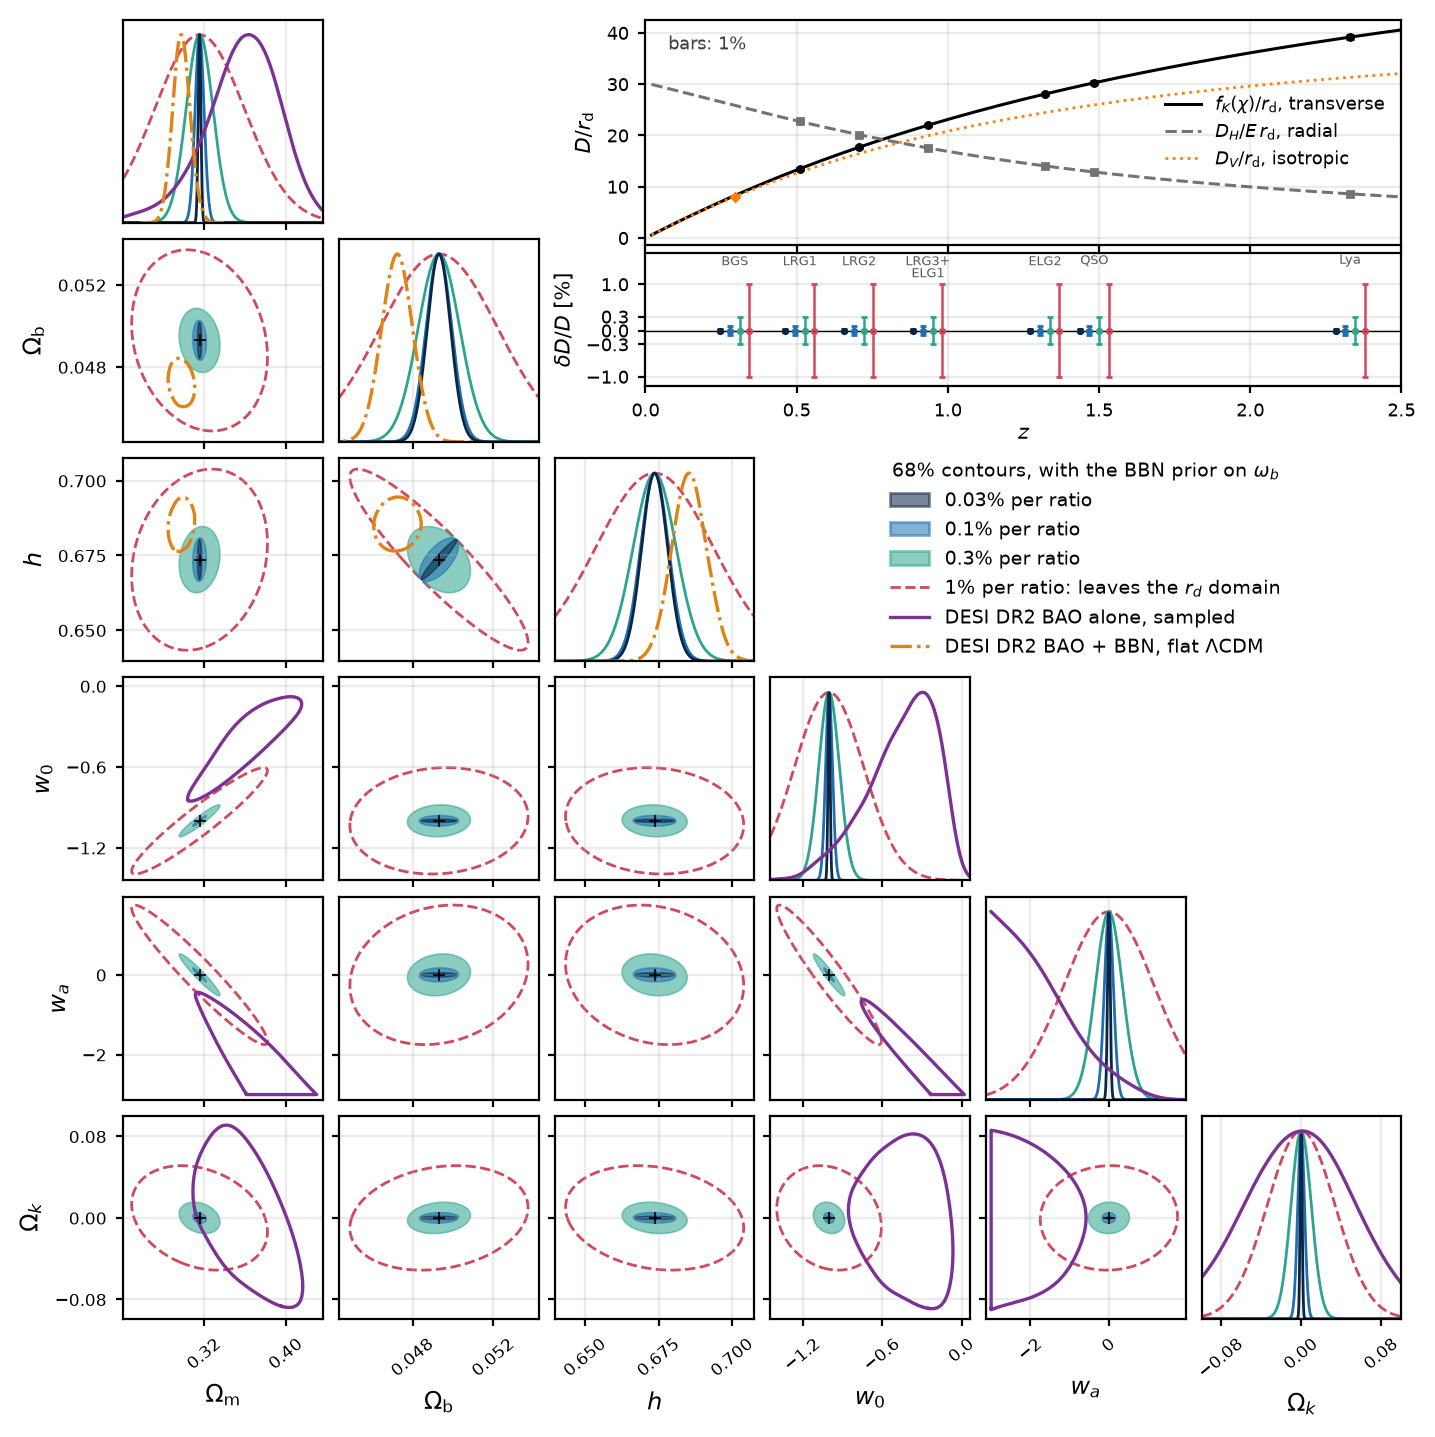

In [8]:
fig = plt.figure(figsize=(7.1, 7.1))
gs = fig.add_gridspec(npar, npar, hspace=0.08, wspace=0.08, left=0.085, right=0.985, bottom=0.07, top=0.985)
half = 1.7 * np.sqrt(np.diag(cov[SIGMAS[-1]]))
lims = []
for i in range(npar):
    lo, hi = t0[i] - half[i], t0[i] + half[i]
    for k in STYLE:
        v = [poly[:, 0] for q in DESI.parameters(k) if q != P[i] for poly in DESI.contours(k, P[i], q)]
        if v:
            v = np.concatenate(v)
            pad = 0.05 * np.ptp(v)
            lo, hi = min(lo, v.min() - pad), max(hi, v.max() + pad)
    lims.append((lo, hi))

for i in range(npar):
    for j in range(i + 1):
        a = fig.add_subplot(gs[i, j])
        a.set_xlim(lims[j])
        a.tick_params(labelsize=6.2, length=2.5)
        a.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(3))
        if i == j:
            a.set_yticks([])
            a.set_ylim(0.0, 1.08)
            x = np.linspace(*lims[j], 400)
            for s, col in zip(SIGMAS[::-1], COLOURS[::-1]):
                sd = np.sqrt(cov[s][j, j])
                a.plot(x, np.exp(-0.5 * ((x - t0[j]) / sd) ** 2), color=col, lw=1.0,
                       ls="--" if s in INVALID else "-")
            for k, st in STYLE.items():
                if P[j] in DESI.parameters(k):
                    a.plot(*DESI.marginal(k, P[j]), **st)
        else:
            a.set_ylim(lims[i])
            a.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(3))
            for s, col in zip(SIGMAS[::-1], COLOURS[::-1]):
                c2 = cov[s][np.ix_([j, i], [j, i])]
                if s in INVALID:
                    T.fisher_ellipse(a, (t0[j], t0[i]), c2, fill=False, ec=col, lw=1.0, ls="--")
                else:
                    T.fisher_ellipse(a, (t0[j], t0[i]), c2, fc=col, alpha=0.55, ec=col, lw=0.6)
            for k, st in STYLE.items():
                for poly in DESI.contours(k, P[j], P[i]):
                    a.plot(poly[:, 0], poly[:, 1], **st)
            a.plot(t0[j], t0[i], "+", color="k", ms=4, mew=0.6)
        if i == npar - 1:
            a.set_xlabel(T.TEX[P[j]], fontsize=8.5)
            for lab in a.get_xticklabels():
                lab.set_rotation(40)
        else:
            a.tick_params(labelbottom=False)
        if j == 0 and i > 0:
            a.set_ylabel(T.TEX[P[i]], fontsize=8.5)
        else:
            a.tick_params(labelleft=False)

sub = gs[0:2, 2:6].subgridspec(3, 2, height_ratios=(1.7, 1.0, 0.36), width_ratios=(0.12, 1.0),
                               hspace=0.06, wspace=0.0)
ad, ae = fig.add_subplot(sub[0, 1]), fig.add_subplot(sub[1, 1])
zz = np.linspace(0.02, 2.5, 200)
dz = np.asarray(ln_bao(jnp.asarray(t0), zz))
m = len(zz)
for a in (ad, ae):
    a.tick_params(labelsize=6.5, length=2.5)
    a.set_xlim(0.0, 2.5)
ad.plot(zz, np.exp(dz[:m]), color="k", lw=1.1, label=r"$f_K(\chi)/r_{\rm d}$, transverse")
ad.plot(zz, np.exp(dz[m:]), color="0.45", lw=1.1, ls="--", label=r"$D_H/E\,r_{\rm d}$, radial")
ad.plot(zz, np.exp((np.log(zz) + 2 * dz[:m] + dz[m:]) / 3), color="C1", lw=1.0, ls=":",
        label=r"$D_V/r_{\rm d}$, isotropic")
dk, dr = np.exp(d0[:n]), np.exp(d0[n:])
dv = np.exp((np.log(Z) + 2 * d0[:n] + d0[n:]) / 3)
ad.errorbar(Z[~ISO], dk[~ISO], yerr=0.01 * dk[~ISO], fmt="o", ms=2.2, color="k", capsize=1.5, lw=0.8)
ad.errorbar(Z[~ISO], dr[~ISO], yerr=0.01 * dr[~ISO], fmt="s", ms=2.0, color="0.45", capsize=1.5, lw=0.8)
ad.errorbar(Z[ISO], dv[ISO], yerr=0.01 * dv[ISO], fmt="D", ms=2.2, color="C1", capsize=1.5, lw=0.8)
ad.set_ylabel(r"$D/r_{\rm d}$", fontsize=7.5)
ad.tick_params(labelbottom=False)
ad.legend(fontsize=6.5, loc="center right", frameon=False)
ad.text(0.03, 0.93, "bars: 1%", transform=ad.transAxes, fontsize=6.5, va="top", color="0.25")
for k, (s, col) in enumerate(zip(SIGMAS, COLOURS)):
    ae.errorbar(Z + (k - 1.5) * 0.032, np.zeros(n), yerr=100 * s, fmt="o", ms=1.6, color=col, capsize=1.0,
                lw=0.9, ls="none", mfc="none" if s in INVALID else col)
ae.axhline(0.0, color="k", lw=0.5)
ae.set_ylim(-1.2, 1.67)
ae.set_yticks([-1, -0.3, 0, 0.3, 1])
ae.set_xlabel("$z$", fontsize=7.5, labelpad=1)
ae.set_ylabel(r"$\delta D/D$ [%]", fontsize=7.5)
for zi, name in zip(Z, TRACER):
    ae.text(zi, 1.64, name.replace("+", "+\n"), fontsize=4.8, ha="center", va="top", color="0.35", linespacing=0.9)

al = fig.add_subplot(gs[2, 3:6])
al.axis("off")
hand = [Line2D([], [], color=col, ls="--", lw=1.0) if s in INVALID else Patch(fc=col, ec=col, alpha=0.55)
        for s, col in zip(SIGMAS, COLOURS)]
labs = [f"{100 * s:g}% per ratio" + (": leaves the $r_d$ domain" if refused_at[s] else "") for s in SIGMAS]
hand += [Line2D([], [], **st) for st in STYLE.values()]
labs += [LABEL[k] for k in STYLE]
al.legend(hand, labs, loc="center", fontsize=7, frameon=False,
          title=r"68% contours, with the BBN prior on $\omega_b$", title_fontsize=7);
T.save_figure(fig, "fig_distance_fisher")

## Check against the paper

In [9]:
quoted = [("sigma(Omega_m) 1%", sd1[0], 0.043), ("sigma(Omega_b) 1%", sd1[1], 0.0029), ("sigma(h) 1%", sd1[2], 0.020),
          ("sigma(w0) 1%", sd1[3], 0.26), ("sigma(wa) 1%", sd1[4], 1.1), ("sigma(Omega_k) 1%", sd1[5], 0.034),
          ("sigma(h) ratio 1%/0.1%", ratio_h, 4.2), ("z_p", z_p, 0.27), ("sigma(w_p)", sig_wp, 0.082),
          ("max chi2 at 0.03%", chi2max[0.0003], 1.07), ("max chi2 at 0.1%", chi2max[0.001], 1.03),
          ("max chi2 at 0.3%", chi2max[0.003], 1.19)]
for label, here, paper in quoted:
    print(f"{label:24s} here {here:.3g}   paper {paper:.3g}")
    assert abs(here / paper - 1) < 0.05, label
assert INVALID == {0.01}
print("Sec. 4.1 reproduced")

sigma(Omega_m) 1%        here 0.0439   paper 0.043
sigma(Omega_b) 1%        here 0.00291   paper 0.0029
sigma(h) 1%              here 0.02   paper 0.02
sigma(w0) 1%             here 0.26   paper 0.26
sigma(wa) 1%             here 1.15   paper 1.1
sigma(Omega_k) 1%        here 0.0338   paper 0.034
sigma(h) ratio 1%/0.1%   here 4.17   paper 4.2
z_p                      here 0.273   paper 0.27
sigma(w_p)               here 0.0821   paper 0.082
max chi2 at 0.03%        here 1.07   paper 1.07
max chi2 at 0.1%         here 1.03   paper 1.03
max chi2 at 0.3%         here 1.19   paper 1.19
Sec. 4.1 reproduced


## Exercises

1. Free $\sum m_\nu$ and $T_{\rm CMB}$ at 1 per cent. What are their errors, and how much does $\sigma(\Omega_{\rm m})$ grow?
2. Use DESI DR2's own errors and the $-0.40$ to $-0.50$ correlations between $f_K/r_{\rm d}$ and $D_H/E\,r_{\rm d}$ in each bin (Table IV of Abdul Karim et al. 2025). Compare your errors with the purple contours.
3. Keep only the transverse ratios, then only the radial ones. Why is $\Omega_k$ constrained only by the two together?

Next: notebook 08, constraints from the full shape of the power spectrum.